# Cap. 3: Regressão linear aplicada a WDO e WIN

**Objetivo:** levar o capítulo 3 do curso para os mesmos dados do [cap. 2](ch02_statistical_learning.ipynb). O cap. 2 perguntou *quão bem se prevê*; aqui a pergunta é *o que dá para afirmar sobre cada variável*, com estimativas, erros-padrão, intervalos de confiança e testes.

| Aula | Pergunta aqui |
|---|---|
| 3.1 Regressão simples | Quanto o \|retorno\| do próximo minuto sobe a cada bp de \|retorno\| agora? Com que precisão? |
| 3.2 Regressão múltipla | Quais features importam quando entram juntas? O modelo como um todo explica algo (teste F)? |
| 3.3 Outras considerações | Horário como variável qualitativa, interações, termos não lineares e os problemas da regressão (resíduos, heterocedasticidade, autocorrelação, outliers, alavancagem, colinearidade). |
| 3.5 Linear × KNN | A regressão linear, mais elaborada, se aproxima do KNN fora da amostra? |

**Dados:** os mesmos do cap. 2 (`src/dataset.py`): barras de 1 minuto, 9 features conhecidas no fechamento do minuto e dois alvos do minuto seguinte, a **intensidade** (`abs_fwd`, \|retorno\| em bps) e a **direção** (`fwd`, retorno em bps). **Toda a inferência usa só o treino** (70% iniciais dos pregões). O teste só entra para medir a previsão fora da amostra (seções 4, 6 e 7), nunca para escolher o modelo.

**Erros-padrão:** sempre HAC (Newey-West), que levam em conta a variância que muda no tempo e a correlação entre minutos vizinhos ([notebook 00](00_exploracao_wdo_win.ipynb), seção 4). Quando a diferença importa, o erro-padrão comum aparece ao lado.

Os conceitos usados estão no [glossário](../GLOSSARIO.md#regressão-linear-islp-cap-3).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import OLSInfluence, variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.dataset import FEATURES, carregar, dividir

FIG = ROOT / "figures"
plt.rcParams["figure.figsize"] = (11, 4)
HAC = dict(cov_type="HAC", cov_kwds={"maxlags": 5})   # erros-padrão de Newey-West

dados = carregar()
treino, teste = dividir(dados, frac_treino=0.7)
pd.DataFrame({r: {"treino": f"{treino[r].index[0]:%d/%m} a {treino[r].index[-1]:%d/%m} ({len(treino[r]):,} min)",
                  "teste": f"{teste[r].index[0]:%d/%m} a {teste[r].index[-1]:%d/%m} ({len(teste[r]):,} min)"}
              for r in dados})

,WDO,WIN
treino,"20/10 a 10/11 (8,469 min)","20/10 a 10/11 (8,392 min)"
teste,"11/11 a 19/11 (3,962 min)","11/11 a 19/11 (3,923 min)"


In [2]:
def coeficientes(m):
    # tabela de coeficientes com erro-padrão, t, p-valor e intervalo de confiança de 95%
    ic = m.conf_int()
    return pd.DataFrame({"coef": m.params, "erro-padrão": m.bse, "t": m.tvalues, "p-valor": m.pvalues,
                         "IC 95% inf.": ic[0], "IC 95% sup.": ic[1]})


def r2_fora(m, root, alvo="abs_fwd"):
    # R² fora da amostra: 1 - MSE no teste / MSE de prever sempre a média do treino
    te = teste[root]
    ingenuo = ((te[alvo] - treino[root][alvo].mean()) ** 2).mean()
    return 1 - ((te[alvo] - m.predict(te)) ** 2).mean() / ingenuo

## 1. Regressão simples (aula 3.1)

$\text{abs\_fwd} = \beta_0 + \beta_1 \cdot \text{abs\_ret} + \varepsilon$: quanto o \|retorno\| do próximo minuto muda, em média, a cada bp de \|retorno\| no minuto atual. A tabela mostra o mesmo ajuste com o erro-padrão comum (que supõe erros independentes e de variância constante) e com o HAC. O coeficiente é o mesmo; muda só a incerteza em volta dele.

O **RSE** (*residual standard error*) é o desvio-padrão do erro: quanto o \|retorno\| real se afasta, tipicamente, da reta.

In [3]:
rows, simples = [], {}
for root, d in treino.items():
    comum = smf.ols("abs_fwd ~ abs_ret", d).fit()
    hac = smf.ols("abs_fwd ~ abs_ret", d).fit(**HAC)
    simples[root] = hac
    for nome, m in [("comum", comum), ("HAC", hac)]:
        ic = m.conf_int().loc["abs_ret"]
        rows.append({"ativo": root, "erro-padrão": nome, "beta_0": m.params["Intercept"], "beta_1": m.params["abs_ret"],
                     "erro-padrão de beta_1": m.bse["abs_ret"], "t": m.tvalues["abs_ret"], "p-valor": m.pvalues["abs_ret"],
                     "IC 95% de beta_1": f"[{ic[0]:.3f}; {ic[1]:.3f}]", "R²": m.rsquared, "RSE (bps)": np.sqrt(comum.scale)})
pd.DataFrame(rows).set_index(["ativo", "erro-padrão"]).round(4)

beta_0  beta_1  erro-padrão de beta_1        t  p-valor  \
ativo erro-padrão                                                            
WDO   comum        1.7416  0.3058                 0.0103  29.6075      0.0   
      HAC          1.7416  0.3058                 0.0229  13.3436      0.0   
WIN   comum        2.6920  0.3458                 0.0102  33.8781      0.0   
      HAC          2.6920  0.3458                 0.0244  14.1908      0.0   

                  IC 95% de beta_1      R²  RSE (bps)  
ativo erro-padrão                                      
WDO   comum         [0.286; 0.326]  0.0938     2.6180  
      HAC           [0.261; 0.351]  0.0938     2.6180  
WIN   comum         [0.326; 0.366]  0.1203     4.5257  
      HAC           [0.298; 0.394]  0.1203     4.5257

**O que os números mostram**
- **O efeito:** cada bp de \|retorno\| no minuto atual aumenta o \|retorno\| do minuto seguinte, em média, em 0,31 bp no WDO e 0,35 bp no WIN. Um minuto parado (`abs_ret` = 0) é seguido, em média, de 1,7 bp (WDO) e 2,7 bps (WIN): é o intercepto.
- **O HAC muda a incerteza, não a estimativa.** O erro-padrão de $\beta_1$ fica 2,2 vezes maior no WDO (de 0,010 para 0,023) e 2,4 vezes no WIN, e o intervalo de confiança alarga (no WDO, de [0,286; 0,326] para [0,261; 0,351]). Mesmo assim, t = 13 a 14 e p-valor ≈ 0: o efeito é medido com muita precisão.
- **Significativo não é o mesmo que forte.** O R² é de 9,4% (WDO) e 12,0% (WIN), e o RSE é de 2,6 e 4,5 bps, do tamanho do próprio \|retorno\| típico. O \|retorno\| atual explica uma parte pequena do seguinte, mas essa parte é muito bem medida.

### 1.1 Intervalo de confiança × intervalo de previsão

Para um minuto com \|retorno\| atual de x bps:
- o **intervalo de confiança** diz onde está a **média** do \|retorno\| seguinte de todos os minutos com esse x;
- o **intervalo de previsão** diz onde deve cair o \|retorno\| seguinte de **um** minuto específico. Ele inclui o erro irredutível e por isso é muito mais largo.

O intervalo de previsão aqui supõe erros normais e de variância constante, o que não vale para estes dados (caudas gordas, volatilidade que muda). Ele serve para mostrar a diferença de escala entre os dois intervalos, não como previsão de risco.

previsão (bps) IC 95% da média  \
ativo abs_ret atual (bps)                                   
WDO   1.0                            2.05    [1.98; 2.12]   
      5.0                            3.27    [3.12; 3.42]   
      20.0                           7.86    [7.04; 8.67]   
WIN   1.0                            3.04    [2.90; 3.17]   
      5.0                            4.42    [4.28; 4.56]   
      20.0                           9.61   [8.79; 10.43]   

                          intervalo de previsão 95%  
ativo abs_ret atual (bps)                            
WDO   1.0                             [-3.08; 7.18]  
      5.0                             [-1.86; 8.40]  
      20.0                            [2.66; 13.05]  
WIN   1.0                            [-5.83; 11.91]  
      5.0                            [-4.45; 13.29]  
      20.0                            [0.70; 18.52]

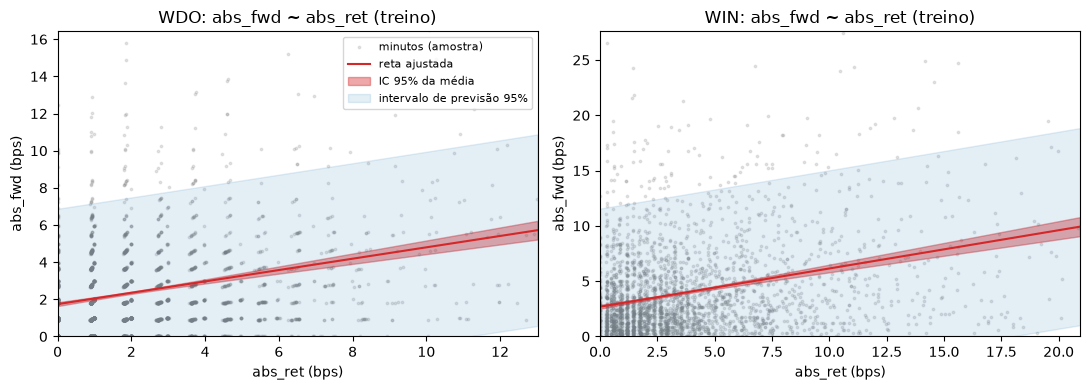

In [4]:
rows = []
for root, m in simples.items():
    x = pd.DataFrame({"abs_ret": [1.0, 5.0, 20.0]})
    pr = m.get_prediction(x).summary_frame(alpha=0.05)
    for xi, (_, r) in zip(x["abs_ret"], pr.iterrows()):
        rows.append({"ativo": root, "abs_ret atual (bps)": xi, "previsão (bps)": r["mean"],
                     "IC 95% da média": f"[{r['mean_ci_lower']:.2f}; {r['mean_ci_upper']:.2f}]",
                     "intervalo de previsão 95%": f"[{r['obs_ci_lower']:.2f}; {r['obs_ci_upper']:.2f}]"})
display(pd.DataFrame(rows).set_index(["ativo", "abs_ret atual (bps)"]).round(2))

fig, axes = plt.subplots(1, 2)
for ax, (root, m) in zip(axes, simples.items()):
    d = treino[root]
    lo, hi = d["abs_ret"].quantile([0, 0.99])
    grade = pd.DataFrame({"abs_ret": np.linspace(lo, hi, 100)})
    pr = m.get_prediction(grade).summary_frame(alpha=0.05)
    amostra = d.sample(3000, random_state=0)
    ax.scatter(amostra["abs_ret"], amostra["abs_fwd"], s=3, alpha=0.2, color="gray", label="minutos (amostra)")
    ax.plot(grade["abs_ret"], pr["mean"], color="tab:red", label="reta ajustada")
    ax.fill_between(grade["abs_ret"], pr["mean_ci_lower"], pr["mean_ci_upper"], color="tab:red", alpha=0.4, label="IC 95% da média")
    ax.fill_between(grade["abs_ret"], pr["obs_ci_lower"].clip(lower=0), pr["obs_ci_upper"], color="tab:blue", alpha=0.12, label="intervalo de previsão 95%")
    ax.set_xlim(lo, hi)
    ax.set_ylim(0, d["abs_fwd"].quantile(0.995))
    ax.set_title(f"{root}: abs_fwd ~ abs_ret (treino)")
    ax.set_xlabel("abs_ret (bps)")
    ax.set_ylabel("abs_fwd (bps)")
axes[0].legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "ch03_simples.png", dpi=110)

**O que os números mostram**
- **O intervalo de confiança da média é estreito.** Para um minuto de 5 bps no WDO, a média do \|retorno\| seguinte está entre 3,12 e 3,42 bps.
- **O intervalo de previsão é dezenas de vezes mais largo:** de −1,86 a 8,40 bps para o mesmo minuto. É o erro irredutível do cap. 2: o modelo diz muito sobre a média de muitos minutos e pouco sobre um minuto específico.
- **O intervalo de previsão inclui valores negativos**, impossíveis para um \|retorno\|. É um sinal de que a premissa de erros normais e de variância constante não vale aqui: o \|retorno\| é sempre ≥ 0, tem cauda gorda e varia mais nos minutos agitados (seção 5).

## 2. Regressão múltipla (aula 3.2)

Agora com as 9 features juntas. Cada coeficiente passa a ser o efeito de uma feature **mantendo as outras fixas**, por isso ele pode ser bem diferente do coeficiente da regressão simples da mesma feature.

In [5]:
formula_9 = "abs_fwd ~ " + " + ".join(FEATURES)
multipla = {root: smf.ols(formula_9, d).fit(**HAC) for root, d in treino.items()}
pd.concat({root: coeficientes(m) for root, m in multipla.items()}, names=["ativo", "feature"]).round(4)

coef  erro-padrão       t  p-valor  IC 95% inf.  \
ativo feature                                                         
WDO   Intercept  -0.6848       0.2879 -2.3783   0.0174      -1.2492   
      ret        -0.0202       0.0159 -1.2760   0.2019      -0.0513   
      ret_l1     -0.0123       0.0138 -0.8945   0.3710      -0.0393   
      ret_l2     -0.0111       0.0122 -0.9052   0.3654      -0.0351   
      abs_ret     0.1464       0.0181  8.0995   0.0000       0.1110   
      abs_ret_l1  0.1849       0.0214  8.6422   0.0000       0.1430   
      abs_ret_l2  0.1204       0.0153  7.8531   0.0000       0.0904   
      imbalance   0.0427       0.1012  0.4215   0.6734      -0.1557   
      log_vol     0.2870       0.0370  7.7656   0.0000       0.2146   
      minuto     -0.0011       0.0002 -6.6851   0.0000      -0.0014   
WIN   Intercept   4.5197       1.3471  3.3552   0.0008       1.8795   
      ret         0.0034       0.0269  0.1278   0.8983      -0.0492   
      ret_l1     -0.0035       0.0133 -0.2645   0.7914      -0.0296   
      ret_l2      0.0479       0.0222  2.1558   0.0311       0.0043   
      abs_ret     0.2328       0.0260  8.9513   0.0000       0.1818   
      abs_ret_l1  0.1194       0.0259  4.6114   0.0000       0.0686   
      abs_ret_l2  0.1857       0.0316  5.8766   0.0000       0.1238   
      imbalance  -0.3042       0.6013 -0.5059   0.6130      -1.4826   
      log_vol    -0.1606       0.1269 -1.2658   0.2056      -0.4093   
      minuto     -0.0035       0.0005 -7.4424   0.0000      -0.0044   

                  IC 95% sup.  
ativo feature                  
WDO   Intercept       -0.1204  
      ret              0.0108  
      ret_l1           0.0147  
      ret_l2           0.0129  
      abs_ret          0.1818  
      abs_ret_l1       0.2269  
      abs_ret_l2       0.1505  
      imbalance        0.2410  
      log_vol          0.3595  
      minuto          -0.0008  
WIN   Intercept        7.1599  
      ret              0.0561  
      ret_l1           0.0226  
      ret_l2           0.0914  
      abs_ret          0.2837  
      abs_ret_l1       0.1701  
      abs_ret_l2       0.2477  
      imbalance        0.8743  
      log_vol          0.0881  
      minuto          -0.0026

### 2.1 Teste F: o modelo inteiro e grupos de features

O teste t olha uma feature de cada vez. O **teste F** testa várias ao mesmo tempo, por exemplo "todos os coeficientes são zero" (o modelo não explica nada) ou "as duas defasagens de \|retorno\| juntas não acrescentam nada". Com erros HAC, o teste F é feito sobre a matriz de covariância robusta.

In [6]:
hipoteses = {
    "todas as 9 features = 0": ", ".join(f"{f} = 0" for f in FEATURES),
    "defasagens de |ret| = 0 (abs_ret_l1, abs_ret_l2)": "abs_ret_l1 = 0, abs_ret_l2 = 0",
    "features de direção = 0 (ret, ret_l1, ret_l2, imbalance)": "ret = 0, ret_l1 = 0, ret_l2 = 0, imbalance = 0",
    "volume e horário = 0 (log_vol, minuto)": "log_vol = 0, minuto = 0",
}
rows = []
for root, m in multipla.items():
    for nome, h in hipoteses.items():
        f = m.f_test(h)
        rows.append({"ativo": root, "hipótese nula": nome, "F": float(np.squeeze(f.fvalue)),
                     "graus de liberdade": f"({int(f.df_num)}, {int(f.df_denom)})", "p-valor": float(f.pvalue)})
pd.DataFrame(rows).set_index(["ativo", "hipótese nula"]).round(4)

F  \
ativo hipótese nula                                                  
WDO   todas as 9 features = 0                              89.5845   
      defasagens de |ret| = 0 (abs_ret_l1, abs_ret_l2)     58.2438   
      features de direção = 0 (ret, ret_l1, ret_l2, i...    1.0464   
      volume e horário = 0 (log_vol, minuto)               83.2428   
WIN   todas as 9 features = 0                             105.7915   
      defasagens de |ret| = 0 (abs_ret_l1, abs_ret_l2)     38.1062   
      features de direção = 0 (ret, ret_l1, ret_l2, i...    1.6694   
      volume e horário = 0 (log_vol, minuto)               50.7645   

                                                         graus de liberdade  \
ativo hipótese nula                                                           
WDO   todas as 9 features = 0                                     (9, 8459)   
      defasagens de |ret| = 0 (abs_ret_l1, abs_ret_l2)            (2, 8459)   
      features de direção = 0 (ret, ret_l1, ret_l2, i...          (4, 8459)   
      volume e horário = 0 (log_vol, minuto)                      (2, 8459)   
WIN   todas as 9 features = 0                                     (9, 8382)   
      defasagens de |ret| = 0 (abs_ret_l1, abs_ret_l2)            (2, 8382)   
      features de direção = 0 (ret, ret_l1, ret_l2, i...          (4, 8382)   
      volume e horário = 0 (log_vol, minuto)                      (2, 8382)   

                                                          p-valor  
ativo hipótese nula                                                
WDO   todas as 9 features = 0                              0.0000  
      defasagens de |ret| = 0 (abs_ret_l1, abs_ret_l2)     0.0000  
      features de direção = 0 (ret, ret_l1, ret_l2, i...   0.3815  
      volume e horário = 0 (log_vol, minuto)               0.0000  
WIN   todas as 9 features = 0                              0.0000  
      defasagens de |ret| = 0 (abs_ret_l1, abs_ret_l2)     0.0000  
      features de direção = 0 (ret, ret_l1, ret_l2, i...   0.1541  
      volume e horário = 0 (log_vol, minuto)               0.0000

**O que os números mostram**
- **O modelo como um todo explica a intensidade:** F = 90 (WDO) e 106 (WIN), com p-valor ≈ 0.
- **As defasagens de \|retorno\| acrescentam informação** além do minuto atual (p-valor ≈ 0 nos dois ativos): a memória da volatilidade vai além de um minuto.
- **As features de direção não acrescentam nada à intensidade.** `ret`, `ret_l1`, `ret_l2` e `imbalance`, juntas, têm p-valor de 0,38 (WDO) e 0,15 (WIN).
- **Volume e horário, juntos, importam** (p-valor ≈ 0). Individualmente, `minuto` é significativo nos dois ativos e `log_vol` só no WDO (seção 2.2).
- O único coeficiente de direção com p-valor abaixo de 0,05 é `ret_l2` no WIN (0,031). Com 9 coeficientes por modelo, um resultado assim é esperado por acaso, e ele não passa no critério de Bonferroni (0,05/9 ≈ 0,0056).

### 2.2 Simples × múltipla e a correlação entre as features

No livro, o gasto com jornal parece afetar as vendas na regressão simples e deixa de afetar na múltipla, porque ele é correlacionado com o gasto em rádio. A mesma coisa pode acontecer aqui. A tabela compara o coeficiente de cada feature sozinha e dentro do modelo com as 9.

In [7]:
rows = []
for root, d in treino.items():
    for f in FEATURES:
        s = smf.ols(f"abs_fwd ~ {f}", d).fit(**HAC)
        rows.append({"ativo": root, "feature": f, "coef simples": s.params[f], "p simples": s.pvalues[f],
                     "coef múltipla": multipla[root].params[f], "p múltipla": multipla[root].pvalues[f]})
display(pd.DataFrame(rows).set_index(["ativo", "feature"]).round(4))
treino["WIN"][["abs_ret", "abs_ret_l1", "abs_ret_l2", "log_vol", "minuto"]].corr().round(2).rename_axis("correlação (WIN, treino)")

coef simples  p simples  coef múltipla  p múltipla
ativo feature                                                       
WDO   ret              -0.0366     0.0294        -0.0202      0.2019
      ret_l1           -0.0318     0.0564        -0.0123      0.3710
      ret_l2           -0.0298     0.0806        -0.0111      0.3654
      abs_ret           0.3058     0.0000         0.1464      0.0000
      abs_ret_l1        0.3190     0.0000         0.1849      0.0000
      abs_ret_l2        0.2668     0.0000         0.1204      0.0000
      imbalance        -0.1517     0.0514         0.0427      0.6734
      log_vol           0.8937     0.0000         0.2870      0.0000
      minuto           -0.0036     0.0000        -0.0011      0.0000
WIN   ret               0.0154     0.5153         0.0034      0.8983
      ret_l1            0.0124     0.5229        -0.0035      0.7914
      ret_l2            0.0542     0.0751         0.0479      0.0311
      abs_ret           0.3458     0.0000         0.2328      0.0000
      abs_ret_l1        0.2851     0.0000         0.1194      0.0000
      abs_ret_l2        0.3122     0.0000         0.1857      0.0000
      imbalance        -0.2016     0.4896        -0.3042      0.6130
      log_vol           1.1773     0.0000        -0.1606      0.2056
      minuto           -0.0068     0.0000        -0.0035      0.0000

,abs_ret,abs_ret_l1,abs_ret_l2,log_vol,minuto
"correlação (WIN, treino)",,,,,
abs_ret,1.00,0.35,0.28,0.36,-0.23
abs_ret_l1,0.35,1.00,0.34,0.26,-0.23
abs_ret_l2,0.28,0.34,1.00,0.21,-0.23
log_vol,0.36,0.26,0.21,1.00,-0.58
minuto,-0.23,-0.23,-0.23,-0.58,1.00


**O que os números mostram**
- **Os coeficientes de \|retorno\| caem à metade ou menos na múltipla** (no WDO, o de `abs_ret` vai de 0,31 para 0,15). Sozinho, o \|retorno\| atual carrega também o efeito das defasagens e do horário, com os quais é correlacionado (0,28 a 0,36 no WIN).
- **O caso do jornal, no WIN:** sozinho, `log_vol` tem coeficiente +1,18 (p-valor ≈ 0). Na múltipla, −0,16 (p-valor 0,21). Volume alto aparece junto com minutos agitados (correlação de 0,36 com `abs_ret`) e com a manhã (−0,58 com `minuto`). Sozinho, o volume "empresta" o efeito dessas variáveis; com elas no modelo, ele não acrescenta nada. Isso explica o coeficiente negativo do `log_vol` no WIN que apareceu no cap. 2.
- **No WDO, o volume continua importando** na múltipla (0,29, p-valor ≈ 0), embora bem menos que sozinho (0,89).
- As correlações são moderadas: elas bastam para mudar os coeficientes, mas não chegam a ser colinearidade séria (seção 5.2).

## 3. Variáveis qualitativas (aula 3.3.1)

Até aqui o horário entrou como `minuto`, uma reta: o modelo supõe que a agitação cai no mesmo ritmo do começo ao fim do dia. Uma alternativa é tratar a **faixa de horário** como variável qualitativa, com uma *dummy* por faixa. Cada coeficiente mede a diferença em relação a uma faixa de referência (a primeira meia hora), sem impor formato.

Também entra uma dummy para **26/10**, o dia do choque pós-eleição, que está no treino: ela mede quanto mais agitado esse dia foi, além do que o \|retorno\| atual já explica.

In [8]:
FAIXAS = [9, 9.5, 10, 12, 14, 16, 17.5, 18 + 35 / 60]
NOMES_FAIXAS = ["09:00-09:30", "09:30-10:00", "10:00-12:00", "12:00-14:00", "14:00-16:00", "16:00-17:30", "17:30-fim"]


def com_faixa(d):
    d = d.copy()
    d["faixa"] = pd.cut(d.index.hour + d.index.minute / 60, FAIXAS, right=False, labels=NOMES_FAIXAS).astype(str)
    d["choque_26_10"] = (d.index.normalize() == "2026-10-26").astype(int)
    return d


treino = {r: com_faixa(d) for r, d in treino.items()}
teste = {r: com_faixa(d) for r, d in teste.items()}
# log_vol centralizado na média do treino, usado na interação da seção 4
for r in treino:
    media = treino[r]["log_vol"].mean()
    treino[r]["log_vol_c"] = treino[r]["log_vol"] - media
    teste[r]["log_vol_c"] = teste[r]["log_vol"] - media

base = "abs_fwd ~ abs_ret + abs_ret_l1 + abs_ret_l2 + log_vol"
qualit = {root: smf.ols(base + " + C(faixa) + choque_26_10", d).fit(**HAC) for root, d in treino.items()}
tab = pd.concat({root: coeficientes(m) for root, m in qualit.items()}, names=["ativo", "termo"])
display(tab[tab.index.get_level_values(1).str.contains("faixa|choque")].round(3))

rows = []
for root, m in qualit.items():
    nomes = [n for n in m.params.index if n.startswith("C(faixa)")]
    f = m.f_test(", ".join(f"{n} = 0" for n in nomes))
    rows.append({"ativo": root, "hipótese nula": "todas as faixas de horário = 0", "F": float(np.squeeze(f.fvalue)), "p-valor": float(f.pvalue),
                 "R² treino (minuto linear)": smf.ols(base + " + minuto", treino[root]).fit().rsquared,
                 "R² treino (faixas + 26/10)": m.rsquared})
pd.DataFrame(rows).set_index("ativo").round(4)

coef  erro-padrão       t  p-valor  \
ativo termo                                                          
WDO   C(faixa)[T.09:30-10:00] -0.346        0.197  -1.755    0.079   
      C(faixa)[T.10:00-12:00] -0.136        0.174  -0.781    0.435   
      C(faixa)[T.12:00-14:00] -0.545        0.169  -3.223    0.001   
      C(faixa)[T.14:00-16:00] -0.735        0.177  -4.154    0.000   
      C(faixa)[T.16:00-17:30] -0.790        0.177  -4.456    0.000   
      C(faixa)[T.17:30-fim]   -0.641        0.190  -3.366    0.001   
      choque_26_10             2.128        0.232   9.187    0.000   
WIN   C(faixa)[T.09:30-10:00]  0.268        0.411   0.651    0.515   
      C(faixa)[T.10:00-12:00]  1.319        0.238   5.541    0.000   
      C(faixa)[T.12:00-14:00] -0.088        0.238  -0.370    0.711   
      C(faixa)[T.14:00-16:00] -0.426        0.253  -1.686    0.092   
      C(faixa)[T.16:00-17:30] -0.576        0.273  -2.109    0.035   
      C(faixa)[T.17:30-fim]   -0.588        0.390  -1.508    0.132   
      choque_26_10             4.804        0.412  11.656    0.000   

                               IC 95% inf.  IC 95% sup.  
ativo termo                                              
WDO   C(faixa)[T.09:30-10:00]       -0.732        0.040  
      C(faixa)[T.10:00-12:00]       -0.478        0.206  
      C(faixa)[T.12:00-14:00]       -0.876       -0.214  
      C(faixa)[T.14:00-16:00]       -1.082       -0.388  
      C(faixa)[T.16:00-17:30]       -1.137       -0.442  
      C(faixa)[T.17:30-fim]         -1.014       -0.268  
      choque_26_10                   1.674        2.582  
WIN   C(faixa)[T.09:30-10:00]       -0.539        1.074  
      C(faixa)[T.10:00-12:00]        0.852        1.785  
      C(faixa)[T.12:00-14:00]       -0.553        0.378  
      C(faixa)[T.14:00-16:00]       -0.922        0.069  
      C(faixa)[T.16:00-17:30]       -1.112       -0.041  
      C(faixa)[T.17:30-fim]         -1.351        0.176  
      choque_26_10                   3.996        5.611

,hipótese nula,F,p-valor,R² treino (minuto linear),R² treino (faixas + 26/10)
ativo,,,,,
WDO,todas as faixas de horário = 0,10.4054,0.0,0.1845,0.2156
WIN,todas as faixas de horário = 0,19.2329,0.0,0.1976,0.2425


**O que os números mostram**
- **O horário importa:** as faixas, juntas, têm F = 10,4 (WDO) e 19,2 (WIN), com p-valor ≈ 0.
- **O formato é diferente nos dois ativos**, e uma reta em `minuto` não consegue representar isso. No WDO, em relação à primeira meia hora, a agitação cai a partir das 12h (−0,5 a −0,8 bp, mantendo o resto fixo). No WIN, a faixa das 10h às 12h é *mais* agitada que a abertura (+1,3 bp, p-valor ≈ 0), e a tarde tende a ser menos agitada (−0,4 a −0,6 bp, mas só a faixa das 16h às 17h30 tem p-valor abaixo de 0,05). É o mesmo formato do volume no [notebook 00](00_exploracao_wdo_win.ipynb) (seção 2), com o pico do WIN entre 10h e 12h.
- **O dia 26/10 foi mais agitado do que o \|retorno\| de cada minuto indica:** +2,1 bps no WDO e +4,8 bps no WIN em relação a um minuto igual em outro dia. A dummy não ajuda a prever (26/10 não está no teste), mas impede que esse dia distorça os outros coeficientes.
- O R² do treino sobe de 18,5% para 21,6% (WDO) e de 19,8% para 24,2% (WIN) ao trocar a reta em `minuto` pelas faixas e pela dummy de 26/10. O ganho vem das duas mudanças juntas.

## 4. Interações e termos não lineares (aula 3.3.2)

**Interação (sinergia):** o modelo aditivo supõe que o efeito do \|retorno\| atual é o mesmo com volume alto ou baixo. A interação testa se um minuto agitado **com muito volume** se repete mais (ou menos) do que um minuto agitado com pouco volume. Pelo princípio hierárquico do livro, os efeitos principais (`abs_ret` e `log_vol`) ficam no modelo junto com a interação.

O volume entra na interação **centralizado** (`log_vol_c` = `log_vol` menos a média do treino). Sem isso, num modelo com interação, o coeficiente de `abs_ret` seria o efeito do \|retorno\| quando `log_vol` = 0, um minuto com volume de 1 contrato, que não existe. Com o volume centralizado, ele passa a ser o efeito num minuto de volume médio.

**Não linearidade:** no cap. 2, a curva do KNN achatava nos \|retornos\| altos, mas as médias por faixa mostraram que esse achatamento é viés de borda do KNN, não uma característica dos dados. O termo $\text{abs\_ret}^2$ testa a curvatura com um modelo paramétrico: um coeficiente negativo indicaria que a relação achata; um positivo, que ela acelera.

A tabela mostra o coeficiente novo de cada modelo e o R² no treino e **fora da amostra** (no teste), para ver se o termo que é significativo também ajuda a prever.

In [9]:
modelos = {
    "base (faixas + 26/10)": base + " + C(faixa) + choque_26_10",
    "+ interação abs_ret:log_vol_c": base + " + abs_ret:log_vol_c + C(faixa) + choque_26_10",
    "+ abs_ret²": base + " + I(abs_ret ** 2) + C(faixa) + choque_26_10",
    "+ interação + abs_ret²": base + " + abs_ret:log_vol_c + I(abs_ret ** 2) + C(faixa) + choque_26_10",
}
rows, ajustados = [], {}
for root, d in treino.items():
    for nome, formula in modelos.items():
        m = smf.ols(formula, d).fit(**HAC)
        ajustados[(root, nome)] = m
        linha = {"ativo": root, "modelo": nome, "R² treino (%)": 100 * m.rsquared, "R² fora da amostra (%)": 100 * r2_fora(m, root)}
        for termo in ["abs_ret", "abs_ret:log_vol_c", "I(abs_ret ** 2)"]:
            if termo in m.params:
                linha[f"coef {termo}"] = m.params[termo]
                linha[f"p {termo}"] = m.pvalues[termo]
        rows.append(linha)
pd.DataFrame(rows).set_index(["ativo", "modelo"]).round(4)

R² treino (%)  R² fora da amostra (%)  \
ativo modelo                                                                 
WDO   base (faixas + 26/10)                21.5586                 12.3127   
      + interação abs_ret:log_vol_c        21.6954                 13.1015   
      + abs_ret²                           21.6048                 13.2203   
      + interação + abs_ret²               21.6961                 13.0069   
WIN   base (faixas + 26/10)                24.2470                 22.4017   
      + interação abs_ret:log_vol_c        24.6851                 20.8342   
      + abs_ret²                           25.0274                 22.1845   
      + interação + abs_ret²               25.3613                 20.8592   

                                     coef abs_ret  p abs_ret  \
ativo modelo                                                   
WDO   base (faixas + 26/10)                0.1003     0.0000   
      + interação abs_ret:log_vol_c        0.0545     0.0018   
      + abs_ret²                           0.0653     0.0785   
      + interação + abs_ret²               0.0574     0.0756   
WIN   base (faixas + 26/10)                0.1441     0.0000   
      + interação abs_ret:log_vol_c        0.1964     0.0000   
      + abs_ret²                           0.0082     0.8236   
      + interação + abs_ret²               0.0629     0.1634   

                                     coef abs_ret:log_vol_c  \
ativo modelo                                                  
WDO   base (faixas + 26/10)                             NaN   
      + interação abs_ret:log_vol_c                  0.0440   
      + abs_ret²                                        NaN   
      + interação + abs_ret²                         0.0466   
WIN   base (faixas + 26/10)                             NaN   
      + interação abs_ret:log_vol_c                 -0.1064   
      + abs_ret²                                        NaN   
      + interação + abs_ret²                        -0.0933   

                                     p abs_ret:log_vol_c  \
ativo modelo                                               
WDO   base (faixas + 26/10)                          NaN   
      + interação abs_ret:log_vol_c               0.0091   
      + abs_ret²                                     NaN   
      + interação + abs_ret²                      0.0877   
WIN   base (faixas + 26/10)                          NaN   
      + interação abs_ret:log_vol_c               0.0000   
      + abs_ret²                                     NaN   
      + interação + abs_ret²                      0.0004   

                                     coef I(abs_ret ** 2)  p I(abs_ret ** 2)  
ativo modelo                                                                  
WDO   base (faixas + 26/10)                           NaN                NaN  
      + interação abs_ret:log_vol_c                   NaN                NaN  
      + abs_ret²                                   0.0026             0.3676  
      + interação + abs_ret²                      -0.0004             0.9135  
WIN   base (faixas + 26/10)                           NaN                NaN  
      + interação abs_ret:log_vol_c                   NaN                NaN  
      + abs_ret²                                   0.0043             0.0007  
      + interação + abs_ret²                       0.0040             0.0035

O termo quadrático do WIN depende de 26/10, o dia com os minutos de maior alavancagem (seção 5.1)? O mesmo modelo, sem a dummy de 26/10, ajustado com e sem esse dia:

In [10]:
rows = []
formula_q = base + " + I(abs_ret ** 2) + C(faixa)"
for root, d in treino.items():
    for nome, x in [("todos os pregões do treino", d), ("sem 26/10", d[d.index.normalize() != "2026-10-26"])]:
        m = smf.ols(formula_q, x).fit(**HAC)
        rows.append({"ativo": root, "amostra": nome, "coef abs_ret²": m.params["I(abs_ret ** 2)"],
                     "p-valor": m.pvalues["I(abs_ret ** 2)"], "maior abs_ret (bps)": x["abs_ret"].max()})
pd.DataFrame(rows).set_index(["ativo", "amostra"]).round(5)

coef abs_ret²  p-valor  maior abs_ret (bps)
ativo amostra                                                                
WDO   todos os pregões do treino        0.00372  0.23736             37.79362
      sem 26/10                         0.00314  0.08172             32.40894
WIN   todos os pregões do treino        0.00302  0.01350             78.08879
      sem 26/10                         0.00704  0.00000             78.08879

**O que os números mostram**
- **A interação tem sinais opostos nos dois ativos.** No WDO, +0,044 (p-valor 0,009): com mais volume, um minuto agitado se repete *mais*. No WIN, −0,106 (p-valor ≈ 0): se repete *menos*.
- **Significativa no treino não quer dizer útil fora dele.** No WDO, a interação melhora o R² fora da amostra (de 12,3% para 13,1%). No WIN, piora (de 22,4% para 20,8%), apesar do p-valor ≈ 0 no treino.
- **O termo quadrático é positivo e significativo no WIN** (+0,0043, p-valor 0,0007): nos \|retornos\| altos, o minuto seguinte cresce *mais* que proporcionalmente. Isso confirma as médias por faixa do [cap. 2](ch02_statistical_learning.ipynb) (seção 1), onde a curva real não achata; o achatamento visto ali vinha do KNN (viés de borda). No WDO, o termo não é significativo (p-valor 0,37). A curvatura do WIN não vem de 26/10: sem esse dia, o coeficiente fica maior (tabela abaixo).
- **O R² do treino sempre sobe quando se acrescenta um termo** (de 24,2% para 25,4% no WIN), como o erro de treino do cap. 2. Fora da amostra, o melhor modelo é o "+ abs_ret²" no WDO (13,2%) e o "base" no WIN (22,4%).
- Com o volume centralizado, o coeficiente de `abs_ret` nos modelos com interação é o efeito num minuto de volume médio. Nos modelos com o termo quadrático, ele é a inclinação da curva perto de `abs_ret` = 0, e por isso fica pequeno.

## 5. Problemas da regressão (aula 3.3.3)

Os seis problemas do livro, verificados no modelo completo da seção 4 (base + interação + \|retorno\|², treino):
1. **Não linearidade:** os resíduos têm padrão contra o valor ajustado?
2. **Correlação dos erros:** o erro de um minuto ajuda a prever o do seguinte?
3. **Variância não constante (heterocedasticidade):** o tamanho do erro cresce com o valor ajustado?
4. **Outliers:** minutos com resíduo muito grande.
5. **Pontos de alavancagem:** minutos com valores de X incomuns, que puxam a reta.
6. **Colinearidade:** features tão correlacionadas que o modelo não consegue separar o efeito de cada uma.

,"autocorrelação dos resíduos, lag 1",Durbin-Watson (2 = sem autocorrelação),Breusch-Pagan: p-valor,"corr(|resíduo|, ajustado)"
ativo,,,,
WDO,-0.0133,2.0265,0.0,0.4327
WIN,-0.0108,2.0213,0.0,0.4732


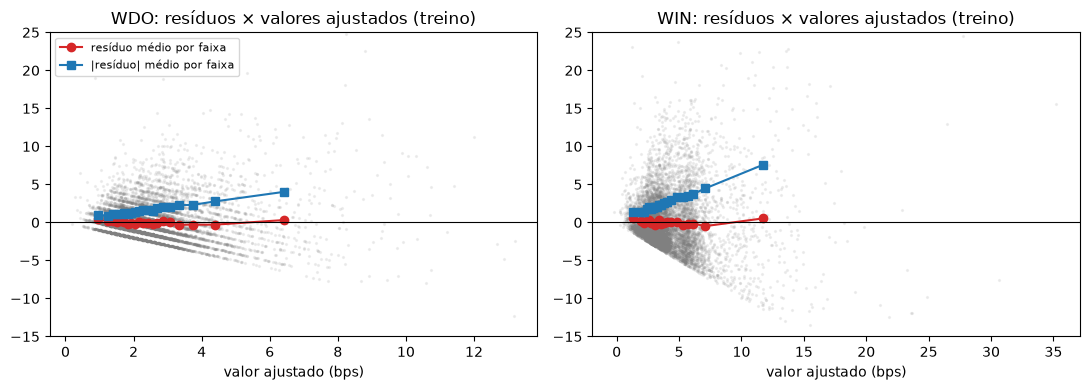

In [11]:
completo = {root: ajustados[(root, "+ interação + abs_ret²")] for root in treino}
fig, axes = plt.subplots(1, 2)
for ax, (root, m) in zip(axes, completo.items()):
    aj, res = m.fittedvalues, m.resid
    faixas_aj = pd.qcut(aj, 20, duplicates="drop")
    medias = pd.DataFrame({"aj": aj, "res": res, "abs_res": res.abs()}).groupby(faixas_aj, observed=True).mean()
    ax.scatter(aj, res, s=2, alpha=0.1, color="gray")
    ax.plot(medias["aj"], medias["res"], "o-", color="tab:red", label="resíduo médio por faixa")
    ax.plot(medias["aj"], medias["abs_res"], "s-", color="tab:blue", label="|resíduo| médio por faixa")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_ylim(-15, 25)
    ax.set_title(f"{root}: resíduos × valores ajustados (treino)")
    ax.set_xlabel("valor ajustado (bps)")
axes[0].legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG / "ch03_residuos.png", dpi=110)

rows = []
for root, m in completo.items():
    res = m.resid
    rows.append({"ativo": root,
                 "autocorrelação dos resíduos, lag 1": res.autocorr(1),
                 "Durbin-Watson (2 = sem autocorrelação)": durbin_watson(res),
                 "Breusch-Pagan: p-valor": het_breuschpagan(res, m.model.exog)[1],
                 "corr(|resíduo|, ajustado)": res.abs().corr(m.fittedvalues)})
pd.DataFrame(rows).set_index("ativo").round(4)

**O que os números mostram**
1. **Não linearidade:** o resíduo médio por faixa de valor ajustado fica perto de zero em toda a faixa. Depois das faixas de horário, da interação e do termo quadrático, não sobra um padrão sistemático.
2. **Correlação dos erros: desprezível.** A autocorrelação dos resíduos no lag 1 é −0,01, e o Durbin-Watson é 2,03 (WDO) e 2,02 (WIN), praticamente o valor de erros independentes (2).
3. **Heterocedasticidade: forte.** O teste de Breusch-Pagan tem p-valor ≈ 0, e o tamanho do resíduo cresce com o valor ajustado (correlação de 0,43 no WDO e 0,47 no WIN), o funil do gráfico. É por isso que o erro-padrão HAC da seção 1 sai mais que o dobro do comum: o que pesa aqui é a variância que muda, mais do que a autocorrelação.
- O livro sugere transformar Y (por exemplo, usar log Y) para reduzir a heterocedasticidade. Aqui isso esbarra nos minutos com \|retorno\| zero, frequentes no WDO por causa do tick grande. Os erros-padrão robustos resolvem a inferência sem transformar Y.
- A borda inferior reta no gráfico vem de o \|retorno\| não poder ser negativo: o resíduo nunca fica abaixo de −(valor ajustado).

### 5.1 Outliers, alavancagem e influência

- **Resíduo estudentizado:** o resíduo dividido pelo seu erro-padrão. Numa distribuição normal, só 0,27% passariam de 3 em valor absoluto.
- **Alavancagem** (*leverage*): o quanto os valores de X de um minuto são incomuns. A média é (p+1)/n; valores muito acima disso indicam minutos que, sozinhos, podem puxar a reta.
- **Distância de Cook:** combina as duas coisas e mede quanto os coeficientes mudam se o minuto for retirado.

Depois, o modelo é reajustado sem os 1% de minutos mais influentes, para ver o quanto o coeficiente de `abs_ret` depende deles.

In [12]:
rows, dias_influentes = [], {}
for root, m in completo.items():
    inf = OLSInfluence(smf.ols(m.model.formula, treino[root]).fit())
    estud = pd.Series(inf.resid_studentized_external, index=m.resid.index)
    alav = pd.Series(inf.hat_matrix_diag, index=m.resid.index)
    cook = pd.Series(inf.cooks_distance[0], index=m.resid.index)
    p_mais_1 = len(m.params)
    top = cook.nlargest(int(0.01 * len(cook))).index
    sem_top = smf.ols(m.model.formula, treino[root].drop(index=top)).fit(**HAC)
    dias_influentes[root] = pd.Series(top.normalize()).value_counts().head(3)
    rows.append({"ativo": root, "minutos": len(estud),
                 "% com |resíduo estud.| > 3": 100 * (estud.abs() > 3).mean(),
                 "alavancagem média (p+1)/n": p_mais_1 / len(alav),
                 "% com alavancagem > 3× a média": 100 * (alav > 3 * p_mais_1 / len(alav)).mean(),
                 "coef abs_ret (todos)": m.params["abs_ret"],
                 "coef abs_ret (sem os 1% mais influentes)": sem_top.params["abs_ret"],
                 "R² treino (todos)": m.rsquared, "R² treino (sem os 1%)": sem_top.rsquared})
display(pd.DataFrame(rows).set_index("ativo").round(4).T)
pd.concat(dias_influentes, names=["ativo", "dia"]).rename("minutos entre os 1% mais influentes").to_frame()

ativo,WDO,WIN
minutos,8469.0000,8392.0000
% com |resíduo estud.| > 3,1.6767,1.4418
alavancagem média (p+1)/n,0.0017,0.0017
% com alavancagem > 3× a média,2.6449,2.4309
coef abs_ret (todos),0.0574,0.0629
coef abs_ret (sem os 1% mais influentes),0.0487,0.0209
R² treino (todos),0.2170,0.2536
R² treino (sem os 1%),0.1695,0.2141


minutos entre os 1% mais influentes
ativo dia                                            
WDO   2026-10-26                                   58
      2026-10-27                                    8
      2026-11-03                                    4
WIN   2026-10-26                                   66
      2026-10-23                                    7
      2026-10-28                                    5

**O que os números mostram**
- **Outliers:** 1,7% (WDO) e 1,4% (WIN) dos minutos têm \|resíduo estudentizado\| acima de 3, contra 0,27% numa distribuição normal, de 5 a 6 vezes mais. São as caudas gordas do [notebook 00](00_exploracao_wdo_win.ipynb) (seção 3).
- **Alavancagem:** 2,6% (WDO) e 2,4% (WIN) dos minutos têm alavancagem acima de 3 vezes a média.
- **Influência concentrada em um dia:** entre os minutos mais influentes (1% do treino: 84 no WDO e 83 no WIN), 58 (WDO) e 66 (WIN) são de 26/10.
- **Sem esses minutos, o modelo muda.** O coeficiente linear de `abs_ret` cai de 0,057 para 0,049 no WDO e de 0,063 para 0,021 no WIN, e o R² do treino cai de 21,7% para 17,0% (WDO) e de 25,4% para 21,4% (WIN). Um único pregão sustenta parte do ajuste, e é por isso que o estudo usa a dummy de 26/10 e mostra as análises com e sem esse dia.

### 5.2 Colinearidade

O **VIF** (*variance inflation factor*) de uma feature diz quantas vezes a variância do seu coeficiente aumenta por causa da correlação com as outras features. VIF = 1 é nenhuma colinearidade; o livro considera problemático acima de 5 a 10. Aqui ele é calculado para as 9 features da seção 2.

In [13]:
rows = {}
for root, d in treino.items():
    X = d[FEATURES].assign(const=1.0)
    rows[root] = {f: variance_inflation_factor(X.values, i) for i, f in enumerate(FEATURES)}
pd.DataFrame(rows).round(2).rename_axis("VIF")

,WDO,WIN
VIF,,
ret,1.33,1.68
ret_l1,1.02,1.01
ret_l2,1.01,1.01
abs_ret,1.37,1.28
abs_ret_l1,1.24,1.26
abs_ret_l2,1.21,1.20
imbalance,1.33,1.68
log_vol,1.74,1.66
minuto,1.35,1.55


**O que os números mostram**
- **Não há colinearidade séria.** O VIF fica entre 1,0 e 1,7 em todas as features, longe do limite de 5 a 10 do livro.
- As correlações moderadas (até −0,58, entre `log_vol` e `minuto`) bastam para mudar coeficientes entre a regressão simples e a múltipla (seção 2.2), mas não tornam as estimativas instáveis: os erros-padrão da múltipla continuam pequenos. O que acontece com o volume no WIN é **confusão** (ele está correlacionado com variáveis que de fato explicam a intensidade), não colinearidade.

## 6. O alvo sem sinal: a direção do próximo minuto

O mesmo modelo de 9 features, agora para a **direção** (`fwd`, retorno com sinal). O teste F diz se o conjunto explica algo. Com 9 coeficientes testados, é esperado que algum dê p-valor abaixo de 0,05 por acaso (em média 0,45), então o critério de Bonferroni (0,05/9 ≈ 0,0056) também aparece. O modelo é ajustado com as duas versões do fluxo de agressão (`imbalance` e `imbalance_sem_diretos`, ver [notebook 00](00_exploracao_wdo_win.ipynb), seção 5).

In [14]:
rows = []
for root, d in treino.items():
    for versao in ["imbalance", "imbalance_sem_diretos"]:
        feats = [f if f != "imbalance" else versao for f in FEATURES]
        m = smf.ols("fwd ~ " + " + ".join(feats), d).fit(**HAC)
        f = m.f_test(", ".join(f"{x} = 0" for x in feats))
        p = m.pvalues.drop("Intercept")
        rows.append({"ativo": root, "fluxo": versao, "F (todas = 0)": float(np.squeeze(f.fvalue)), "p-valor do F": float(f.pvalue),
                     "R² treino (%)": 100 * m.rsquared, "R² fora da amostra (%)": 100 * r2_fora(m, root, "fwd"),
                     "features com p < 0,05": ", ".join(p[p < 0.05].index) or "nenhuma",
                     "features com p < 0,0056 (Bonferroni)": ", ".join(p[p < 0.05 / 9].index) or "nenhuma"})
pd.DataFrame(rows).set_index(["ativo", "fluxo"]).round(4)

F (todas = 0)  p-valor do F  R² treino (%)  \
ativo fluxo                                                               
WDO   imbalance                     1.6047        0.1077         0.3403   
      imbalance_sem_diretos         1.7053        0.0820         0.3541   
WIN   imbalance                     1.7784        0.0669         0.7918   
      imbalance_sem_diretos         1.7037        0.0824         0.7851   

                             R² fora da amostra (%)  \
ativo fluxo                                           
WDO   imbalance                             -0.1585   
      imbalance_sem_diretos                 -0.1755   
WIN   imbalance                             -0.3884   
      imbalance_sem_diretos                 -0.3777   

                                      features com p < 0,05  \
ativo fluxo                                                   
WDO   imbalance                                     abs_ret   
      imbalance_sem_diretos  abs_ret, imbalance_sem_diretos   
WIN   imbalance                            abs_ret, log_vol   
      imbalance_sem_diretos                abs_ret, log_vol   

                            features com p < 0,0056 (Bonferroni)  
ativo fluxo                                                       
WDO   imbalance                                          nenhuma  
      imbalance_sem_diretos                              nenhuma  
WIN   imbalance                                          nenhuma  
      imbalance_sem_diretos                              nenhuma

**O que os números mostram**
- **O conjunto não explica a direção.** O teste F tem p-valor de 0,11 (WDO) e 0,07 (WIN); sem os negócios diretos, 0,08 nos dois. Nenhum chega a 0,05.
- **Fora da amostra, o modelo é pior que prever a média:** R² de −0,2% (WDO) e −0,4% (WIN). No treino, ele explica só 0,3% a 0,8%.
- **Alguns coeficientes isolados têm p-valor abaixo de 0,05** (`abs_ret` nos dois ativos, `log_vol` no WIN e `imbalance_sem_diretos` no WDO), mas nenhum passa no critério de Bonferroni. Com 9 coeficientes por modelo, o acaso produz em média 0,45 resultado assim.
- É a mesma conclusão do [notebook 00](00_exploracao_wdo_win.ipynb) e do [cap. 2](ch02_statistical_learning.ipynb): com estas features, a direção do próximo minuto é imprevisível, com ou sem os negócios diretos.

## 7. Linear × KNN fora da amostra (aula 3.5)

A comparação do fim do capítulo: o modelo linear mais elaborado (faixas de horário, dummy de 26/10, interação e termo quadrático, todos escolhidos olhando só o treino) contra o KNN do cap. 2, no mesmo teste. O K de cada ativo é o melhor do cap. 2 (K=100 no WDO e K=500 no WIN), que **foi escolhido olhando o teste**; isso favorece o KNN na comparação.

In [15]:
K_CAP2 = {"WDO": 100, "WIN": 500}
rows = {}
for root in treino:
    tr, te = treino[root], teste[root]
    ingenuo = ((te["abs_fwd"] - tr["abs_fwd"].mean()) ** 2).mean()
    knn = make_pipeline(StandardScaler(), KNeighborsRegressor(K_CAP2[root])).fit(tr[FEATURES], tr["abs_fwd"])
    rows[root] = {"linear, 9 features (cap. 2)": 100 * r2_fora(smf.ols(formula_9, tr).fit(), root),
                  "linear, faixas + 26/10": 100 * r2_fora(ajustados[(root, "base (faixas + 26/10)")], root),
                  "linear, + interação + abs_ret²": 100 * r2_fora(ajustados[(root, "+ interação + abs_ret²")], root),
                  f"KNN do cap. 2 (9 features)": 100 * (1 - ((te["abs_fwd"] - knn.predict(te[FEATURES])) ** 2).mean() / ingenuo)}
pd.DataFrame(rows).round(2).rename_axis("R² fora da amostra (%)")

,WDO,WIN
R² fora da amostra (%),,
"linear, 9 features (cap. 2)",11.52,19.98
"linear, faixas + 26/10",12.31,22.40
"linear, + interação + abs_ret²",13.01,20.86
KNN do cap. 2 (9 features),11.44,24.16


**O que os números mostram**
- **No WDO, o linear elaborado vence o KNN:** 13,0% de R² fora da amostra, contra 11,4% do KNN e 11,5% da linear simples com 9 features.
- **No WIN, o KNN ainda vence** (24,2%), à frente do melhor linear (22,4%, com faixas de horário e a dummy de 26/10). Mas o K do KNN foi escolhido olhando o teste, o que o favorece.
- **O que mais ajudou o linear foram as faixas de horário:** no WIN, de 20,0% para 22,4%. A interação e o termo quadrático, significativos no treino, pioraram o WIN fora da amostra.
- É o que o livro diz na seção 3.5: um modelo paramétrico compete bem quando a forma que ele supõe está perto da verdadeira. Aqui, a relação é quase linear no \|retorno\| (cap. 2, seção 1), e o principal desvio da reta, o formato do dia, é captado pelas faixas.

## Conclusões

**Amostra:** 22 pregões, de 20/10 a 19/11/2026. A inferência usa o treino (20/10 a 10/11, 15 pregões); o teste (11/11 a 19/11, 7 pregões) só mede previsão fora da amostra.

1. **A intensidade do próximo minuto é previsível e bem medida.** Cada bp de \|retorno\| atual acrescenta 0,31 bp (WDO) e 0,35 bp (WIN) ao seguinte, com t de 13 a 14 mesmo com erros HAC. Mas o \|retorno\| atual sozinho explica só 9% a 12% da variância, e o modelo completo, 22% a 25% no treino: a maior parte é erro irredutível.
2. **A direção não é previsível.** O teste F de todas as features não chega a 0,05, nenhum coeficiente passa no critério de Bonferroni e o R² fora da amostra é negativo, com ou sem os negócios diretos.
3. **Simples × múltipla:** o volume do WIN parece importar sozinho (+1,18, p-valor ≈ 0) e deixa de importar quando entram o \|retorno\| e o horário (−0,16, p-valor 0,21). É confusão, não colinearidade (VIF abaixo de 1,8).
4. **O horário tem formato próprio em cada ativo**, que faixas captam e uma reta não. O dia 26/10 acrescenta 2 bps (WDO) e 5 bps (WIN) à agitação de cada minuto.
5. **Significativo no treino não garante melhor previsão.** A interação \|retorno\| × volume tem p-valor ≈ 0 no WIN e piora o R² fora da amostra. A relação com o \|retorno\| é quase linear, com leve aceleração nos extremos no WIN, e não achata.
6. **As premissas clássicas falham, e o estudo leva isso em conta.** Há heterocedasticidade forte (Breusch-Pagan com p-valor ≈ 0), outliers de 5 a 6 vezes a frequência normal e um único dia (26/10) concentrando 70% a 80% dos minutos mais influentes. Por isso os erros-padrão HAC, a dummy de 26/10 e as checagens com e sem esse dia. Já a autocorrelação dos erros é desprezível (Durbin-Watson de 2,0).
7. **Linear × KNN fora da amostra:** o linear vence no WDO (13,0% contra 11,4%) e perde no WIN (22,4% contra 24,2%), num KNN cujo K foi escolhido olhando o teste.